# TOVIS (*TO*nal *VIS*ualization toolbox): _Demo: Bach Chorale_
Johannes Zeitler and Meinard Müller, 2026

**Neural backend:** Install the `transcription` extra (`pip install "tovis[transcription]"`) and obtain a compatible Deep Chroma checkpoint separately; it is not included with TOVIS. Place `checkpoint_deepChroma.pt` in the repository-root `checkpoints/` folder or edit `transcription_checkpoint` below. The example selects `transcription_device="cuda"`, which requires a CUDA-capable GPU and a compatible PyTorch installation; use `transcription_device="cpu"` for CPU inference, which may be slower. To run without neural transcription, switch to `backend="IIR"` (or `"STFT"` or `"CQT"`); the checkpoint and device arguments can then be omitted.

In this demo notebook, we showcase audio-based scale analysis of the Bach chorale "Durch dein Gefängnis, Gottes Sohn" from the St. John Passion (BWV 245).

In [1]:
import matplotlib.pyplot as plt
from IPython.display import Audio
import pandas as pd
import librosa

import os

from tovis.feature import compute_chromagram_from_file
from tovis.scale import scale_analysis_templates
from tovis.visualization import plot_chromagram, plot_scale_likelihood, overlay_measure_annotations, overlay_lines
from tovis.utils import time_to_measures, smooth_resample_feature_sequence

We start by specifying the filenames for the audio recording and the beat annotations. We load the audio and embed an interactive player.

In [2]:
piece = "Bach_BWV245-No22"
version = "VokalensembleIlmenau"
BASE_PATH = os.path.join("data", "BachChoral")

fn_wav = os.path.join(BASE_PATH, piece + "_" + version + ".mp3")
fn_beat = os.path.join(BASE_PATH, piece + "_" + version + ".csv")

beat_annotation = pd.read_csv(fn_beat, sep=",", header=None, names=["time", "measure"])
audio_in, sr_audio = librosa.load(fn_wav, sr=22050, mono=True)
Audio(data=audio_in, rate=sr_audio)

Next, we compute a chromagram from the audio recording. We can choose different feature extraction backends, such as an "STFT" or an "IIR" filterbank. In our example, we choose a "deep_chroma" neural network. We plot the chromagram and overlay measure annotations.

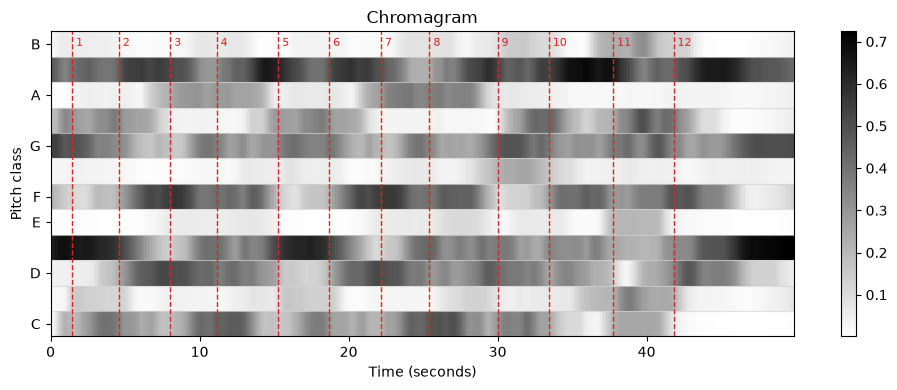

In [3]:
chromagram, sr_chromagram = compute_chromagram_from_file(fn_wav,
                                                         backend="deep_chroma",
                                                         transcription_checkpoint=os.path.join("../", "checkpoints", "checkpoint_deepChroma.pt"),
                                                         transcription_device="cuda",
                                                         smoothing_length_seconds=4,
                                                         output_feature_rate=10)
fig, ax, im = plot_chromagram(chromagram, 
                              feature_rate=sr_chromagram,
                              show_natural_pitch_labels=True)

overlay_measure_annotations(beat_annotation, ax=ax, measure_annotation_hop=1, label_location="top")
#overlay_lines(ax=ax)
fig.tight_layout()
plt.show()


Based on the chromagram, we can compute likelihoods for diatonic scales. To this end, we compare the chromagram features to template vectors for the twelve diatonic scales. Applying a softmax rescaling yields scale likelihoods.

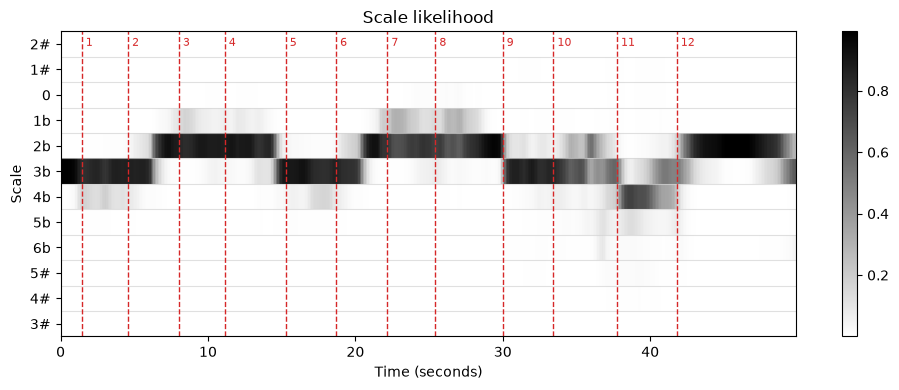

In [4]:
scale_likelihood = scale_analysis_templates(chromagram,
                                            template_version="krumhansl",
                                            method="exp_product",
                                            apply_softmax_rescaling=True,
                                            softmax_eta=10)

fig, ax, im = plot_scale_likelihood(scale_likelihood,
                                    feature_rate=sr_chromagram,
                                    sort_by_fifths=True,
                                    global_key="Eb",
                                    scale_label_version="absolute_diatonic")

overlay_measure_annotations(beat_annotation, ax=ax, measure_annotation_hop=1, label_location="top")
fig.tight_layout()
plt.show()

In a last step, we convert the scale features from a physical time axis (in seconds) to a musical time axis (in measures). Therefore, we use the beat annotations, which can be seen as a mapping between these time axes.

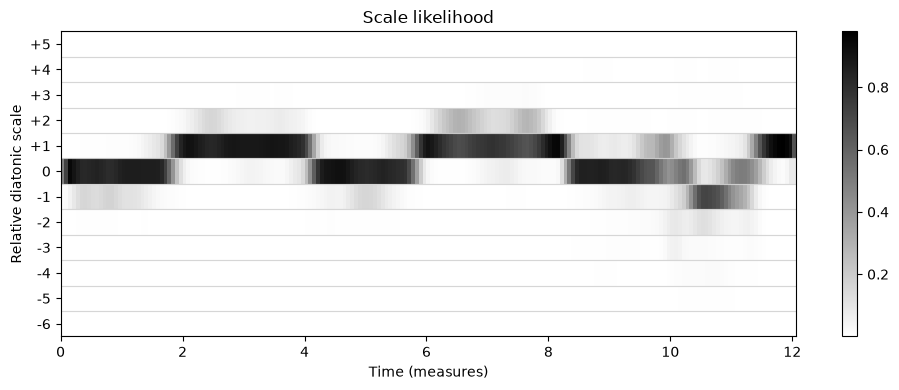

In [5]:
frame_rate_measures = 16
scale_likelihood_measures, measure_axis = time_to_measures(features=scale_likelihood,
                                                           sync_annotation=beat_annotation,
                                                           feature_rate=sr_chromagram,
                                                           frames_per_measure=frame_rate_measures,
                                                           time_column="time",
                                                           measure_column="measure")

scale_likelihood_measures_smooth, _ = smooth_resample_feature_sequence(features=scale_likelihood_measures,
                                                                       feature_rate=frame_rate_measures,
                                                                       smoothing_length_seconds=0.25,
                                                                       output_feature_rate=frame_rate_measures) 

fig, ax, im = plot_scale_likelihood(scale_likelihood_measures_smooth,
                                    feature_rate=frame_rate_measures,
                                    sort_by_fifths=True,
                                    global_key="Eb",
                                    scale_label_version="relative_diatonic",
                                    xlabel="Time (measures)",
                                    ylabel="Relative diatonic scale")
overlay_lines(ax=ax)
fig.tight_layout()
plt.show()